### Problema

Você foi contratado como Cientista de Dados por um banco digital.

Todos os dias, centenas de pessoas solicitam empréstimos.

Atualmente, os analistas avaliam cada solicitação manualmente, tornando o processo demorado.

Seu desafio é desenvolver um modelo capaz de prever se um cliente deve ter seu crédito Aprovado ou Reprovado com base em suas informações financeiras.

Antes de treinar o modelo, será necessário analisar e limpar o conjunto de dados.

Ao final, você utilizará o algoritmo Random Forest para construir o classificador.

Antes do treinamento, você percebe que o banco de dados apresenta diversos problemas que precisam ser corrigidos.

Objetivos

Ao final deste exercício você será capaz de:

* Explorar um dataset;
* Tratar dados inconsistentes;
* Preencher valores ausentes;
* Codificar variáveis categóricas;
* Treinar um Random Forest;
* Avaliar o modelo;
* Descobrir quais variáveis mais influenciam a decisão do banco.

# Carregue o dataset.

Use:

pd.read_csv()

In [26]:
import pandas as pd
df = pd.read_csv('/content/credito_clientes.csv')

Visualize as primeiras linhas.

Dica:

df.head()

In [29]:
df.head()

,id,idade,renda_mensal,tempo_emprego,score_credito,divida_atual,possui_imovel,estado_civil,escolaridade,aprovacao
0,1,25,3200.0,2.0,620.0,4500.0,Não,Solteiro,Superior,Reprovado
1,2,41,8500.0,12.0,780.0,1200.0,Sim,Casado,Superior,Aprovado
2,3,37,6100.0,8.0,710.0,3500.0,Sim,Casado,Médio,Aprovado
3,4,29,2800.0,1.0,590.0,8000.0,Não,Solteiro,Médio,Reprovado
4,5,52,12000.0,20.0,830.0,500.0,Sim,Casado,Pós,Aprovado


1. Quantas linhas e colunas existem?

Dica:

df.shape

In [30]:
df.shape

(40, 10)

2. Existem valores ausentes?

Dica:

df.isnull().sum()

In [31]:
df.isnull().sum()

,0
id,0
idade,0
renda_mensal,1
tempo_emprego,1
score_credito,1
divida_atual,1
possui_imovel,1
estado_civil,0
escolaridade,0
aprovacao,0


3. Existem registros duplicados?

Dica:

df.duplicated().sum()

In [32]:
df.duplicated().sum()

np.int64(0)

---

# Limpeza dos Dados


Remover duplicados.
Preencher valores ausentes das colunas numéricas (média ou mediana).
Preencher possui_imovel com a moda.

Dicas:

* fillna()
* mean()
* median()
* mode()

In [35]:
print(f"Linhas antes de remover duplicados: {df.shape[0]}")
df.drop_duplicates(inplace=True)
print(f"Linhas depois de remover duplicados: {df.shape[0]}")

# Preencher valores ausentes das colunas numéricas com a média
# As colunas numéricas com valores ausentes são renda_mensal, tempo_emprego, score_credito, divida_atual
for col in ['renda_mensal', 'tempo_emprego', 'score_credito', 'divida_atual']:
    if df[col].isnull().any():
        df[col].fillna(df[col].mean(), inplace=True)

# Preencher 'possui_imovel' com a moda (valor mais frequente)
if df['possui_imovel'].isnull().any():
    most_frequent_imovel = df['possui_imovel'].mode()[0]
    df['possui_imovel'].fillna(most_frequent_imovel, inplace=True)

print("\nValores ausentes após o preenchimento:")
print(df.isnull().sum())

Linhas antes de remover duplicados: 40
Linhas depois de remover duplicados: 40

Valores ausentes após o preenchimento:
id               0
idade            0
renda_mensal     0
tempo_emprego    0
score_credito    0
divida_atual     0
possui_imovel    0
estado_civil     0
escolaridade     0
aprovacao        0
dtype: int64


/tmp/ipykernel_1145/2904042042.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
/tmp/ipykernel_1145/2904042042.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

---

# Preparação

Transformar em números:

* possui_imovel
* estado_civil
* escolaridade
* aprovacao

Use:

LabelEncoder()

In [36]:
from sklearn.preprocessing import LabelEncoder

# Lista de colunas para codificar
columns_to_encode = ['possui_imovel', 'estado_civil', 'escolaridade', 'aprovacao']

# Aplicar LabelEncoder a cada coluna
for col in columns_to_encode:
    le = LabelEncoder()
    df[col + '_encoded'] = le.fit_transform(df[col])
    print(f"Original '{col}': {df[col].unique()}")
    print(f"Encoded '{col}_encoded': {df[col + '_encoded'].unique()}\n")

# Exibir as primeiras linhas com as novas colunas codificadas
print("DataFrame com colunas codificadas:")
print(df.head())

Original 'possui_imovel': ['Não' 'Sim']
Encoded 'possui_imovel_encoded': [0 1]

Original 'estado_civil': ['Solteiro' 'Casado' 'Divorciado']
Encoded 'estado_civil_encoded': [2 0 1]

Original 'escolaridade': ['Superior' 'Médio' 'Pós' 'Fundamental']
Encoded 'escolaridade_encoded': [3 1 2 0]

Original 'aprovacao': ['Reprovado' 'Aprovado']
Encoded 'aprovacao_encoded': [1 0]

DataFrame com colunas codificadas:
   id  idade  renda_mensal  tempo_emprego  score_credito  divida_atual  \
0   1     25        3200.0            2.0          620.0        4500.0   
1   2     41        8500.0           12.0          780.0        1200.0   
2   3     37        6100.0            8.0          710.0        3500.0   
3   4     29        2800.0            1.0          590.0        8000.0   
4   5     52       12000.0           20.0          830.0         500.0   

  possui_imovel estado_civil escolaridade  aprovacao  possui_imovel_encoded  \
0           Não     Solteiro     Superior  Reprovado                

# Preparando os Dados

Crie:

X


In [43]:

# Features relevantes para crédito: idade, renda_mensal, tempo_emprego, score_credito, divida_atual,
# e as colunas categóricas que foram codificadas.
features = ['idade', 'renda_mensal', 'tempo_emprego', 'score_credito', 'divida_atual',
            'possui_imovel_encoded', 'estado_civil_encoded', 'escolaridade_encoded']
X = df[features]


Crie:

y

contendo:

* aprovação

In [37]:
y = df['aprovacao']

Separe treino e teste.

Dica:

train_test_split()

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Tamanho do conjunto de treino (X_train): {X_train.shape}")
print(f"Tamanho do conjunto de teste (X_test): {X_test.shape}")
print(f"Tamanho do conjunto de treino (y_train): {y_train.shape}")
print(f"Tamanho do conjunto de teste (y_test): {y_test.shape}")

Tamanho do conjunto de treino (X_train): (28, 8)
Tamanho do conjunto de teste (X_test): (12, 8)
Tamanho do conjunto de treino (y_train): (28,)
Tamanho do conjunto de teste (y_test): (12,)


---

# Random Forest

Importe:

RandomForestClassifier

In [41]:
from sklearn.ensemble import RandomForestClassifier

Treine o modelo.

Dica:

fit()

In [45]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Faça previsões.

Dica:

predict()

In [46]:
y_pred = model.predict(X_test)
print("Previsões realizadas no conjunto de teste.")

Previsões realizadas no conjunto de teste.


# Avaliação

Mostre:

* Accuracy
* Matriz de Confusão
* Classification Report

In [50]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo: {accuracy:.2f}")

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nMatriz de Confusão:")
print(conf_matrix)

# Classification Report
class_report = classification_report(y_test, y_pred)
print("\nRelatório de Classificação:")
print(class_report)

Acurácia do modelo: 1.00

Matriz de Confusão:
[[5 0]
 [0 7]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



---

Perguntas

1. O modelo acertou a maioria das aprovações/reprovações de crédito?

R:

 Sim, o modelo obteve uma acurácia de 1.00 (100%) no conjunto de teste, o que significa que ele acertou todas as previsões de aprovação e reprovação neste conjunto.


2. Qual categoria (aprovado/reprovado) apresentou mais erros?

R:

Ele previu corretamente os 5 casos de 'Aprovado' e os 7 casos de 'Reprovado'.


3. O modelo parece confiável?

R:

 Embora uma acurácia de 100% no conjunto de teste pareça excelente, ela é suspeita, especialmente em um conjunto de dados tão pequeno

---

# Importância das Variáveis

Utilizar:

modelo.feature_importances_

Construir um gráfico de barras.

Responder:

1. Qual variável teve maior influência?
2. O resultado faz sentido para um banco? Justifique.

Características mais importantes:
                 Feature  Importance
1           renda_mensal    0.271332
4           divida_atual    0.185133
3          score_credito    0.180670
2          tempo_emprego    0.139946
0                  idade    0.111626
6   estado_civil_encoded    0.078245
5  possui_imovel_encoded    0.027887
7   escolaridade_encoded    0.005160


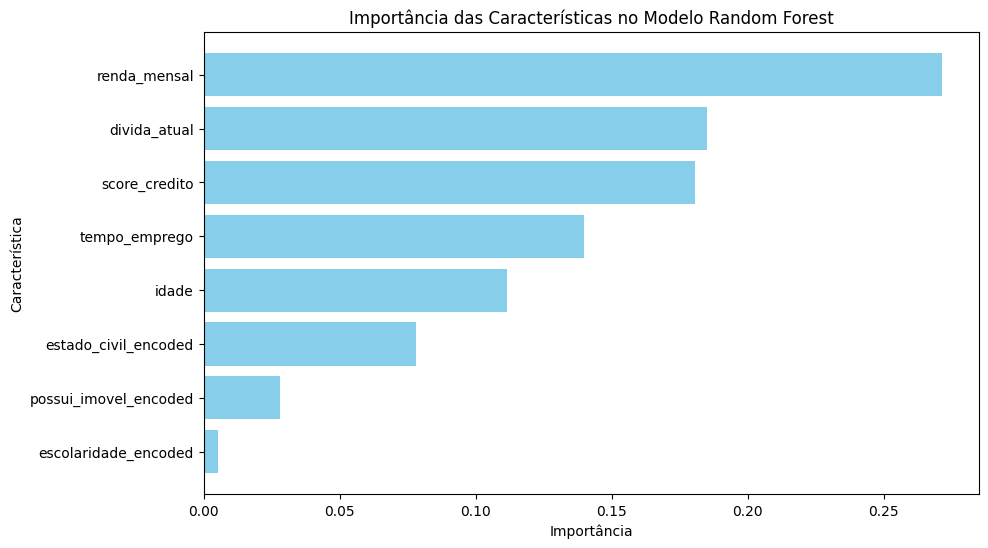

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

# Obtendo a importância das características do modelo
feature_importances = model.feature_importances_
feature_names = X.columns

# Criando um DataFrame para facilitar a visualização e ordenação
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Exibindo as características mais importantes
print("Características mais importantes:")
print(importance_df)

# Construindo o gráfico de barras
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.xlabel('Importância')
plt.ylabel('Característica')
plt.title('Importância das Características no Modelo Random Forest')
plt.gca().invert_yaxis() # Para ter a característica mais importante no topo
plt.show()

---

# Fazendo Novas Previsões

Umm novo cliente possui os seguintes dados:

| Variável         | Valor    |
| ---------------- | -------- |
| Idade            | 38       |
| Renda            | 7200     |
| Tempo de emprego | 9        |
| Score            | 760      |
| Dívida           | 1800     |
| Possui imóvel    | Sim      |
| Estado civil     | Casado   |
| Escolaridade     | Superior |



In [56]:
import pandas as pd

# Dados do novo cliente
new_client_data = {
    'idade': [38],
    'renda_mensal': [7200],
    'tempo_emprego': [9],
    'score_credito': [760],
    'divida_atual': [1800],
    'possui_imovel': ['Sim'],
    'estado_civil': ['Casado'],
    'escolaridade': ['Superior']
}

# Criar DataFrame para o novo cliente
new_client_df = pd.DataFrame(new_client_data)

# Codificar variáveis categóricas manualmente, com base no LabelEncoder original
# 'possui_imovel': 'Não': 0, 'Sim': 1
# 'estado_civil': 'Solteiro': 2, 'Casado': 0, 'Divorciado': 1
# 'escolaridade': 'Superior': 3, 'Médio': 1, 'Pós': 2, 'Fundamental': 0

new_client_df['possui_imovel_encoded'] = new_client_df['possui_imovel'].map({'Não': 0, 'Sim': 1})
new_client_df['estado_civil_encoded'] = new_client_df['estado_civil'].map({'Solteiro': 2, 'Casado': 0, 'Divorciado': 1})
new_client_df['escolaridade_encoded'] = new_client_df['escolaridade'].map({'Superior': 3, 'Médio': 1, 'Pós': 2, 'Fundamental': 0})

# Selecionar e ordenar as colunas para corresponder a X_train
# O 'X.columns' armazena a ordem correta das features usadas no treinamento.
new_client_features = new_client_df[X.columns]

print("Características do novo cliente para previsão:")
print(new_client_features)

# Fazer a previsão usando o modelo RandomForestClassifier treinado
predicted_approval_encoded = model.predict(new_client_features)

# Decodificar o resultado: 'aprovacao_encoded': [1 0] significa 'Reprovado': 1 e 'Aprovado': 0
predicted_approval = 'Aprovado' if predicted_approval_encoded[0] == 0 else 'Reprovado'

print(f"\nPrevisão de aprovação de crédito para o novo cliente: {predicted_approval}")

Características do novo cliente para previsão:
   idade  renda_mensal  tempo_emprego  score_credito  divida_atual  \
0     38          7200              9            760          1800   

   possui_imovel_encoded  estado_civil_encoded  escolaridade_encoded  
0                      1                     0                     3  

Previsão de aprovação de crédito para o novo cliente: Aprovado


---

### Desafio Final

Treine também:

* KNN
* Gaussian Naive Bayes


In [55]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- Treinar KNN ---
print("\n--- Treinando KNN ---")
knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
class_report_knn = classification_report(y_test, y_pred_knn)

print(f"Acurácia do modelo KNN: {accuracy_knn:.2f}")
print("\nMatriz de Confusão KNN:")
print(conf_matrix_knn)
print("\nRelatório de Classificação KNN:")
print(class_report_knn)

# --- Treinar Gaussian Naive Bayes ---
print("\n--- Treinando Gaussian Naive Bayes ---")
gnb_model = GaussianNB()
gnb_model.fit(X_train, y_train)
y_pred_gnb = gnb_model.predict(X_test)

accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
conf_matrix_gnb = confusion_matrix(y_test, y_pred_gnb)
class_report_gnb = classification_report(y_test, y_pred_gnb)

print(f"Acurácia do modelo Gaussian Naive Bayes: {accuracy_gnb:.2f}")
print("\nMatriz de Confusão Gaussian Naive Bayes:")
print(conf_matrix_gnb)
print("\nRelatório de Classificação Gaussian Naive Bayes:")
print(class_report_gnb)



--- Treinando KNN ---
Acurácia do modelo KNN: 1.00

Matriz de Confusão KNN:
[[5 0]
 [0 7]]

Relatório de Classificação KNN:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12


--- Treinando Gaussian Naive Bayes ---
Acurácia do modelo Gaussian Naive Bayes: 0.92

Matriz de Confusão Gaussian Naive Bayes:
[[5 0]
 [1 6]]

Relatório de Classificação Gaussian Naive Bayes:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91         5
           1       1.00      0.86      0.92         7

    accuracy                           0.92        12
   macro avg       0.92      0.93      0.92        12
weighted avg       0.93      0.92      0.92        12

